# Diagnóstico: as 72 regras do passo 5 em 2024 e 2025–26

Feito em 23/11/2026, depois da validação, por curiosidade. **Não serve para escolher regra**: os dois períodos já tinham sido vistos.

In [1]:
# ===== CONFIGURAÇÃO =====
FONTE = "drive"                      # "drive" | "upload" | "local"
CAMINHO_CSV_DRIVE = "/content/drive/MyDrive/data_science_v2/WIN$N_M1.csv"

CANDLES = [1, 5, 15, 30, 60]         # minutos
JANELA_MESES = 12                    # janela de treino fixa neste passo
RODAR_ROBUSTEZ = True                # repete o modelo com janelas de 6 e 24 meses
JANELAS_ROBUSTEZ = [6, 24]

FIM_EXPLORACAO = "2023-12-31"        # análise de dados só até aqui
ANO_SELECAO = 2024
CUSTO_PTS = 5.0
TOL_THEIL = 1.001                    # U <= 1,001 conta como empate com o naive
SEED = 42

RF_PARAMS = dict(n_estimators=200, max_depth=5, min_samples_leaf=0.01,
                 max_features=1.0, max_samples=0.5, n_jobs=-1, random_state=SEED)
FEATURES = ["ret_0", "ret_1", "ret_2", "vol_20", "hora"]

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CORES = {1: "#4C78A8", 5: "#F58518", 15: "#54A24B", 30: "#B279A2", 60: "#E45756"}

try:
    import google.colab  # noqa: F401
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

def localiza_csv():
    """Tenta, em ordem: Drive -> CSV enviado pelo painel lateral (/content) -> upload -> pasta local."""
    nome = "WIN$N_M1.csv"
    if NO_COLAB:
        if FONTE == "drive":
            try:
                from google.colab import drive
                drive.mount("/content/drive")
                if Path(CAMINHO_CSV_DRIVE).exists():
                    return Path(CAMINHO_CSV_DRIVE)
                print(f"Drive montado, mas o arquivo não está em {CAMINHO_CSV_DRIVE}. Procurando no Drive...")
                achados = list(Path("/content/drive/MyDrive").rglob(nome))
                if achados:
                    print("Encontrado em:", achados[0])
                    return achados[0]
            except Exception as erro:
                print(f"Não foi possível montar o Drive ({erro}).")
                print("Alternativa: envie o CSV pelo ícone de pasta à esquerda (Arquivos -> Fazer upload).")
        enviado_painel = Path("/content") / nome
        if enviado_painel.exists():
            return enviado_painel
        from google.colab import files
        print("Selecione o arquivo WIN$N_M1.csv:")
        enviado = files.upload()
        return Path("/content") / next(iter(enviado))
    return next(p / nome for p in [Path.cwd(), Path.cwd().parent] if (p / nome).exists())


ARQ_WIN = localiza_csv()

PASTA_RES = ARQ_WIN.parent / "resultados"
PASTA_RES.mkdir(exist_ok=True)
print("CSV:", ARQ_WIN)
print("Resultados em:", PASTA_RES)

CSV: C:\Users\anabi\Documents\ufg\data_science_v2\WIN$N_M1.csv
Resultados em: C:\Users\anabi\Documents\ufg\data_science_v2\resultados


757,711 candles de 1 min · 2020-10-15 11:49:00 -> 2026-09-25 18:24:00 · 1368 pregões


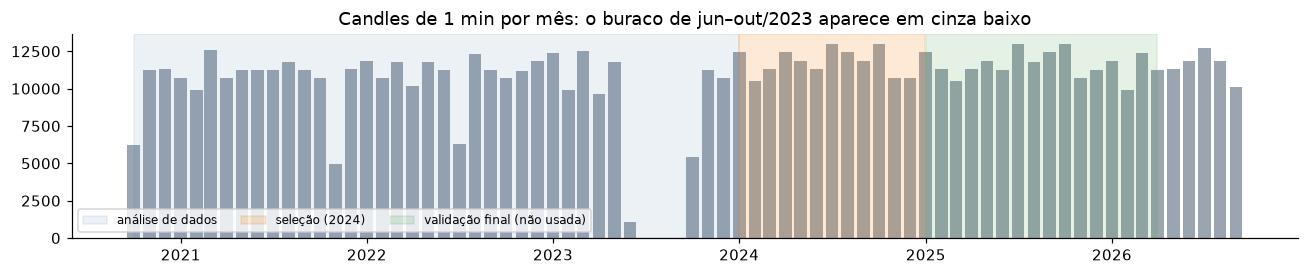

In [3]:
m1 = pd.read_csv(ARQ_WIN, sep="\t")
m1.columns = [c.strip("<>").lower() for c in m1.columns]
m1["dt"] = pd.to_datetime(m1["date"] + " " + m1["time"], format="%Y.%m.%d %H:%M:%S")
m1 = m1.drop(columns=["date", "time", "spread"]).set_index("dt").sort_index()
m1 = m1[~m1.index.duplicated()]
m1 = m1.between_time("09:00", "18:24")          # só o pregão regular

print(f"{len(m1):,} candles de 1 min · {m1.index.min()} -> {m1.index.max()} · "
      f"{m1.index.normalize().nunique()} pregões")

cob = m1.groupby(m1.index.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.bar(cob.index.to_timestamp(), cob.values, width=25, color="#9aa5b1")
ax.axvspan(pd.Timestamp("2020-10-01"), pd.Timestamp(FIM_EXPLORACAO), color="#4C78A8", alpha=0.10, label="análise de dados")
ax.axvspan(pd.Timestamp(f"{ANO_SELECAO}-01-01"), pd.Timestamp(f"{ANO_SELECAO}-12-31"), color="#F58518", alpha=0.18, label="seleção (2024)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31"), color="#54A24B", alpha=0.15, label="validação final (não usada)")
ax.set_title("Candles de 1 min por mês: o buraco de jun–out/2023 aparece em cinza baixo")
ax.legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

In [4]:
m1 = m1[m1.index < "2026-04-01"]

In [5]:
def agrega_candles(m1, minutos):
    if minutos == 1:
        return m1.copy()
    regras = {"open": "first", "high": "max", "low": "min", "close": "last", "tickvol": "sum", "vol": "sum"}
    out = m1.resample(f"{minutos}min", label="left", closed="left").agg(regras)
    return out.dropna(subset=["close"])


def monta_base(m1, minutos):
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    ret = 100 * np.log(df["close"]).groupby(dia).diff()      # NaN no 1º candle do dia

    df["tem_ret_0"] = ret.notna()                             # usado no ρ₁ (exclui o 1º candle)
    df["ret_0"] = ret
    df["ret_1"] = ret.groupby(dia).shift(1)
    df["ret_2"] = ret.groupby(dia).shift(2)
    df["vol_20"] = ret.rolling(20, min_periods=10).std()
    df["hora"] = df.index.hour + df.index.minute / 60
    df["alvo"] = ret.groupby(dia).shift(-1)
    df["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]
    df[["ret_0", "ret_1", "ret_2"]] = df[["ret_0", "ret_1", "ret_2"]].fillna(0.0)
    return df.dropna(subset=["alvo", "vol_20"])




In [6]:
# ===== CONFIGURAÇÃO DO PASSO 2 =====
try:
    CANDLE_P2 = int(escolhido)                     # vem do passo 1
except NameError:
    CANDLE_P2 = json.loads((PASTA_RES / "passo1_escolha.json").read_text())["candle_min"]

JANELA_P2 = 12
ANOS_ESTAB = [2021, 2022, 2023]
LIMIAR_REDUND = 0.8
N_REPETICOES_PERM = 3
RODAR_RETIRADA = True
USAR_WDO = True
print(f"Candle do passo 2: {CANDLE_P2} min")


def localiza_wdo():
    nome = "WDO$N_M1.csv"
    for c in [ARQ_WIN.parent / nome, Path("/content") / nome]:
        if c.exists():
            return c
    if NO_COLAB:
        raiz = Path("/content/drive/MyDrive")
        if raiz.exists():
            achados = list(raiz.rglob(nome))
            if achados:
                return achados[0]
        try:
            from google.colab import files
            print("Selecione o arquivo WDO$N_M1.csv (cancele para seguir sem as features do dólar):")
            enviado = files.upload()
            if enviado:
                return Path("/content") / next(iter(enviado))
        except Exception as erro:
            print("Upload não feito:", erro)
    return None


wdo_m1 = None
if USAR_WDO:
    ARQ_WDO = localiza_wdo()
    if ARQ_WDO is None:
        print("WDO$N_M1.csv não encontrado: seguindo sem as features do dólar.")
    else:
        wdo_m1 = pd.read_csv(ARQ_WDO, sep="\t")
        wdo_m1.columns = [c.strip("<>").lower() for c in wdo_m1.columns]
        wdo_m1["dt"] = pd.to_datetime(wdo_m1["date"] + " " + wdo_m1["time"], format="%Y.%m.%d %H:%M:%S")
        wdo_m1 = wdo_m1.drop(columns=["date", "time", "spread"]).set_index("dt").sort_index()
        wdo_m1 = wdo_m1[~wdo_m1.index.duplicated()].between_time("09:00", "18:24")
        print(f"WDO: {len(wdo_m1):,} candles de 1 min · {wdo_m1.index.min().date()} -> {wdo_m1.index.max().date()}")

Candle do passo 2: 1 min


WDO: 712,996 candles de 1 min · 2020-09-17 -> 2026-04-01


In [7]:
wdo_m1 = wdo_m1[wdo_m1.index < "2026-04-01"]

In [8]:
def monta_base_p2(m1, minutos, wdo_m1=None):
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    lc = np.log(df["close"])
    ret = 100 * lc.groupby(dia).diff()
    r0 = ret.fillna(0.0)
    cs = r0.groupby(dia).cumsum()

    f = pd.DataFrame(index=df.index)
    # retornos
    f["ret_0"] = r0
    f["ret_1"] = ret.groupby(dia).shift(1).fillna(0.0)
    f["ret_2"] = ret.groupby(dia).shift(2).fillna(0.0)
    for k in (5, 15, 60):
        f[f"ret_acum_{k}c"] = cs - cs.groupby(dia).shift(k).fillna(0.0)
    # posição no dia
    f["ret_dia"] = 100 * (lc - np.log(df["open"].groupby(dia).transform("first")))
    hi, lo = df["high"].groupby(dia).cummax(), df["low"].groupby(dia).cummin()
    f["pos_range_dia"] = ((df["close"] - lo) / (hi - lo)).fillna(0.5)
    f["hora"] = df.index.hour + df.index.minute / 60
    # volatilidade
    f["vol_20"] = ret.rolling(20, min_periods=10).std()
    f["vol_60"] = ret.rolling(60, min_periods=20).std()
    f["vol_razao"] = f["vol_20"] / f["vol_60"]
    r1 = 100 * np.log(m1["close"]).groupby(m1.index.normalize()).diff()
    rv = np.sqrt((r1 ** 2).groupby(r1.index.normalize()).sum())          # vol realizada do dia
    f["rv_dia_ant"] = rv.shift(1).reindex(dia).values
    f["rv_media_5d"] = rv.shift(1).rolling(5, min_periods=3).mean().reindex(dia).values
    # forma do candle
    f["range_hl"] = 100 * np.log(df["high"] / df["low"])
    f["corpo"] = 100 * np.log(df["close"] / df["open"])
    f["pos_fech_candle"] = ((df["close"] - df["low"]) / (df["high"] - df["low"])).fillna(0.5)
    # volume relativo ao horário
    hhmm = df.index.hour * 100 + df.index.minute
    media_hor = df["vol"].groupby(hhmm).transform(lambda s: s.shift(1).rolling(20, min_periods=5).mean())
    f["vol_rel"] = df["vol"] / media_hor
    # gap de abertura
    gap = 100 * np.log(df["open"].groupby(dia).first() / df["close"].groupby(dia).last().shift(1))
    f["gap_abertura"] = gap.reindex(dia).fillna(0.0).values
    # dólar
    if wdo_m1 is not None:
        w = agrega_candles(wdo_m1, minutos)
        wd = w.index.normalize()
        wret = 100 * np.log(w["close"]).groupby(wd).diff()
        wcs = wret.fillna(0.0).groupby(wd).cumsum()
        f["wdo_ret_0"] = wret.reindex(df.index).fillna(0.0).values
        f["wdo_ret_acum_15c"] = (wcs - wcs.groupby(wd).shift(15).fillna(0.0)).reindex(df.index).fillna(0.0).values
    # alvo
    f["alvo"] = ret.groupby(dia).shift(-1)
    f["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]
    return f.replace([np.inf, -np.inf], np.nan).dropna()




In [9]:
_p4 = json.loads((PASTA_RES / "passo4_hiperparametros.json").read_text())
FEATS_P5, RF_P5 = _p4["features"], _p4["rf"]
FIM_P5 = pd.Timestamp("2026-04-01")                  # nada daqui em diante entra no passo 5
m1_p5, wdo_p5 = m1[m1.index < FIM_P5], wdo_m1[wdo_m1.index < FIM_P5]
base5 = monta_base_p2(m1_p5, 1, wdo_p5)
assert base5.index.max() < FIM_P5

FOLHAS_P5 = [0.10, 0.05]
CORTES_P5 = [0.30, 0.10, 0.05]                       # fração total das previsões nas duas caudas
cortes_tempo = pd.to_datetime(["2022-01-01", "2022-07-01", "2023-01-01", "2023-07-01", "2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01", "2026-01-01", "2026-04-01"])

partes = []
for folha in FOLHAS_P5:
    for ini, fim in zip(cortes_tempo[:-1], cortes_tempo[1:]):
        tr = base5[(base5.index >= ini - pd.DateOffset(months=_p4["janela"])) & (base5.index < ini)]
        te = base5[(base5.index >= ini) & (base5.index < fim)]
        rf = RandomForestRegressor(n_estimators=RF_P5["n_estimators"], max_depth=RF_P5["max_depth"], min_samples_leaf=folha,
                                   max_features=RF_P5["max_features"], max_samples=min(0.5, RF_P5["lim_linhas_arvore"] / len(tr)),
                                   n_jobs=-1, random_state=SEED).fit(tr[FEATS_P5], tr["alvo"])
        p_tr = rf.predict(tr[FEATS_P5])
        d = pd.DataFrame({"folha": folha, "prev": rf.predict(te[FEATS_P5]), "vol_20": te["vol_20"],
                          "vol_med_treino": tr["vol_20"].median()}, index=te.index)
        for c in CORTES_P5:                          # limiares só com o treino
            d[f"q_sup_{c:g}"], d[f"q_inf_{c:g}"] = np.quantile(p_tr, [1 - c / 2, c / 2])
        partes.append(d)
prev5 = pd.concat(partes)


ref = pd.read_csv(PASTA_RES / "passo4_modelo_final_previsoes_2024.csv", parse_dates=["dt"]).set_index("dt")["prev"]
meu = prev5[(prev5["folha"] == 0.10) & (prev5.index.year == 2024)]["prev"]
dif = (meu - ref).abs()
print(f"Reprodução do passo 4: linhas {len(meu)} x {len(ref)} · maior diferença {dif.max():.1e}")
assert len(meu) == len(ref) and dif.notna().all() and dif.max() < 1e-10
print("Fração de 2022–2024 além dos limiares (esperado: corte/2 por lado):")
print(pd.DataFrame({(f, c): {"compra": (g["prev"] >= g[f"q_sup_{c:g}"]).mean(), "venda": (g["prev"] <= g[f"q_inf_{c:g}"]).mean()}
      for f, g in prev5.groupby("folha") for c in CORTES_P5}).T.round(3).to_string())

Reprodução do passo 4: linhas 141302 x 141302 · maior diferença 1.0e-16
Fração de 2022–2024 além dos limiares (esperado: corte/2 por lado):
           compra  venda
0.05 0.30   0.165  0.131
     0.10   0.058  0.041
     0.05   0.030  0.021
0.10 0.30   0.175  0.127
     0.10   0.065  0.039
     0.05   0.034  0.019


In [10]:
TICK = 5
ULT_ENTRADA, ULT_CANDLE = 17 * 60 + 50, 18 * 60 + 19      # entra até 17:50; zera no fechamento do candle de 18:19 (18:20)


class Mercado:
    """Candles em arrays; fim[i] = último candle utilizável do pregão de i."""
    def __init__(self, candles):
        self.idx = candles.index
        self.o, self.h, self.l, self.c = (candles[x].to_numpy(float) for x in ("open", "high", "low", "close"))
        self.minuto = np.asarray(candles.index.hour * 60 + candles.index.minute)
        self.dia = candles.index.normalize().to_numpy()
        pos = pd.Series(np.arange(len(candles)), index=self.dia)
        util = pos[self.minuto <= ULT_CANDLE].groupby(level=0).max()
        self.fim = pd.Series(self.dia).map(util).fillna(-1).to_numpy(int)

    def pode_entrar(self, t):                              # sinal em t, entrada em t+1
        e = t + 1
        return e < len(self.o) and self.dia[e] == self.dia[t] and self.minuto[e] <= ULT_ENTRADA and e <= self.fim[e]

    def opera(self, t, lado, H, dist_tp, dist_sl):
        """Retorna (i_saida, pontos, motivo, mfe, mae). lado = +1 compra, -1 venda; dist None = sem."""
        e = t + 1
        u = min(e + H - 1, self.fim[e])
        ent = self.o[e]
        hi, lo = self.h[e:u + 1], self.l[e:u + 1]
        fav, adv = (hi - ent, ent - lo) if lado > 0 else (ent - lo, hi - ent)
        js = np.flatnonzero(adv >= dist_sl) if dist_sl else ()
        jt = np.flatnonzero(fav >= dist_tp) if dist_tp else ()
        s = js[0] if len(js) else 10**9
        g = jt[0] if len(jt) else 10**9
        if s <= g and s < 10**9:
            gap = lado * (self.o[e + s] - ent)             # gap além do stop: sai na abertura
            pts, j, mot = min(-dist_sl, gap), s, "stop"
        elif g < 10**9:
            pts, j, mot = dist_tp, g, "tp"
        else:
            j = u - e
            pts, mot = lado * (self.c[u] - ent), "tempo" if u == e + H - 1 else "fim_do_dia"
        return e + j, pts, mot, max(fav[:j + 1].max(), 0), max(adv[:j + 1].max(), 0)


def distancia(m, vol20, fech, H):
    return None if not m else max(TICK, TICK * round(m * vol20 / 100 * fech * np.sqrt(H) / TICK))


def sinais(p, regra):
    c = f"{regra['corte']:g}"
    s = np.where(p["prev"] >= p[f"q_sup_{c}"], 1, np.where(p["prev"] <= p[f"q_inf_{c}"], -1, 0))
    if regra["lado"] == "compra":
        s = np.where(s > 0, s, 0)
    if regra["lado"] == "venda":
        s = np.where(s < 0, s, 0)
    if regra["filtro"] == "manha":
        s = np.where(p.index.hour < 12, s, 0)
    if regra["filtro"] == "vol_alta":
        s = np.where(p["vol_20"] > p["vol_med_treino"], s, 0)
    return s


def simula(p, mk, regra):
    """p: previsões (uma folha, um período); mk: Mercado."""
    s = sinais(p, regra)
    pos = mk.idx.get_indexer(p.index)
    vol = p["vol_20"].to_numpy()
    ops, livre = [], -1
    for k in np.flatnonzero(s):
        t = pos[k]
        if t < livre or t < 0 or not mk.pode_entrar(t):
            continue
        dtp = distancia(regra["tp"], vol[k], mk.c[t], regra["H"])
        dsl = distancia(regra["sl"], vol[k], mk.c[t], regra["H"])
        i, pts, mot, mfe, mae = mk.opera(t, s[k], regra["H"], dtp, dsl)
        ops.append((mk.idx[t], mk.idx[t + 1], mk.idx[i], s[k], pts, mot, mfe, mae, t, vol[k]))
        livre = i
    return pd.DataFrame(ops, columns=["sinal", "entrada", "saida", "lado", "pts", "motivo", "mfe", "mae", "t", "vol_20"])


# ----- testes com candles artificiais -----
def _mk(ohlc, ini="2022-01-03 10:00"):
    return Mercado(pd.DataFrame(ohlc, columns=["open", "high", "low", "close"],
                                index=pd.date_range(ini, periods=len(ohlc), freq="min"), dtype=float))


F = (1000, 1000, 1000, 1000)
for sg in (1, -1):
    def esp(c):                                           # espelha o preço para o lado vendido
        o, h, l, f = c
        return c if sg > 0 else (2000 - o, 2000 - l, 2000 - h, 2000 - f)

    def roda(cs, H, tp, sl, ini="2022-01-03 10:00"):
        return _mk([esp(c) for c in cs], ini).opera(0, sg, H, tp, sl)[:3]

    assert roda([F, (1000, 1060, 990, 1050), F], 2, 50, 50) == (1, 50, "tp")
    assert roda([F, (1000, 1010, 940, 950), F], 2, 50, 50) == (1, -50, "stop")
    assert roda([F, (1000, 1060, 940, 1000), F], 2, 50, 50) == (1, -50, "stop")          # ambos no candle
    assert roda([F, F, (900, 910, 890, 900)], 2, 50, 50) == (2, -100, "stop")            # gap além do stop
    assert roda([F, F, (1100, 1110, 1090, 1100)], 2, 50, 50) == (2, 50, "tp")            # gap a favor: preço-alvo
    assert roda([F, F, (1000, 1030, 990, 1020), F], 2, 50, 50) == (2, 20, "tempo")
    assert roda([F] * 15, 60, None, None, "2022-01-03 18:10")[::2] == (9, "fim_do_dia")  # candle de 18:19
_t = _mk([F] * 5, "2022-01-03 17:48")
assert _t.pode_entrar(0) and _t.pode_entrar(1) and not _t.pode_entrar(2)
_d = pd.DataFrame([F] * 4, columns=["open", "high", "low", "close"], dtype=float,
                  index=pd.to_datetime(["2022-01-03 10:00", "2022-01-03 10:01", "2022-01-04 10:00", "2022-01-04 10:01"]))
assert not Mercado(_d).pode_entrar(1)                                                  # não atravessa pregão
_mm = _mk([F] * 20)
_p = pd.DataFrame({"prev": 1.0, "q_sup_0.1": 0.5, "q_inf_0.1": -0.5, "vol_20": 0.05, "vol_med_treino": 0.01}, index=_mm.idx)
_o = simula(_p, _mm, dict(corte=0.1, lado="ambos", H=5, tp=None, sl=None, filtro="nenhum"))
assert (_o["entrada"].iloc[1:].values > _o["saida"].iloc[:-1].values).all() and len(_o) == 4   # sem sobreposição
print("Testes do motor: ok (compra e venda)")

# sem futuro: truncar os candles depois de t não muda as features em t
_corte = pd.Timestamp("2023-03-15 13:00")
_tr = monta_base_p2(m1_p5[m1_p5.index <= _corte], 1, wdo_p5[wdo_p5.index <= _corte])
_i = _tr.index[-500:]
assert np.allclose(_tr.loc[_i, FEATS_P5], base5.loc[_i, FEATS_P5], rtol=0, atol=1e-10)
print("Teste de futuro: ok")

Testes do motor: ok (compra e venda)


Teste de futuro: ok


In [11]:
mk = Mercado(m1_p5[m1_p5.index >= "2022-01-01"])
dias_todos = pd.DatetimeIndex(np.unique(mk.dia))


def diario(ops, dias, custo=CUSTO_PTS):
    liq = (ops["pts"] - custo).groupby(ops["entrada"].dt.normalize()).sum()
    return liq.reindex(dias, fill_value=0.0)


def ep_mensal(d):
    m = d.groupby(d.index.to_period("M")).mean()
    return m.std(ddof=1) / np.sqrt(len(m))


def mede(ops, dias):
    d = diario(ops, dias)
    r = {"n_ops": len(ops), "bruto_op": ops["pts"].mean(), "liq_op": ops["pts"].mean() - CUSTO_PTS,
         "liq_dia": d.mean(), "ep_dia": ep_mensal(d), "score": d.mean() - ep_mensal(d),
         "acerto": (ops["pts"] > 0).mean()}
    assert abs(d.sum() - (ops["pts"] - CUSTO_PTS).sum()) < 1e-6
    assert (ops["entrada"].dt.normalize() == ops["saida"].dt.normalize()).all()
    for a in sorted(set(dias.year)):
        r[f"n_{a}"] = int((ops["entrada"].dt.year == a).sum())
        r[f"liq_dia_{a}"] = d[d.index.year == a].mean()
    return r


dias_dev = dias_todos[dias_todos.year < 2024]
P_dev = {f: g[g.index.year < 2024] for f, g in prev5.groupby("folha")}
CAMPOS = ["folha", "corte", "lado", "H", "tp", "sl", "filtro"]
ENTRADA = ["folha", "corte", "lado", "H"]
grade, dev_diario = [], {}


def chave(r, campos=CAMPOS):
    return tuple(r[c] for c in campos)


def testa(etapa, regra):
    if chave(regra) in dev_diario:
        return
    ops = simula(P_dev[regra["folha"]], mk, regra)
    dev_diario[chave(regra)] = diario(ops, dias_dev)
    grade.append({"etapa": etapa, **regra, **mede(ops, dias_dev)})


def elegivel(g):
    return (g["n_2022"] >= 100) & (g["n_2023"] >= 100) & (g["liq_dia_2022"] > 0) & (g["liq_dia_2023"] > 0)


def ordena(g):                                            # elegíveis primeiro; depois o score
    return g.assign(elegivel=elegivel(g)).sort_values(["elegivel", "score"], ascending=False)


def regra_de(l):
    return {c: (None if c in ("tp", "sl") and pd.isna(l[c]) else l[c]) for c in CAMPOS}


def n_saidas(r):
    return (r["tp"] is not None) + (r["sl"] is not None)




In [12]:
g = pd.read_csv(PASTA_RES / "passo5_grade.csv")
assert len(g) == 72 and int(g["elegivel"].sum()) == 45
PF = dict(tuple(prev5.groupby("folha")))
rng = np.random.default_rng(SEED)
PER = {"2022-23": (2022, 2023), "2024": (2024, 2024), "2025-26": (2025, 2026)}
out = []
for _, l in g.iterrows():
    r = regra_de(l); o = {"etapa": l["etapa"], **r, "elegivel": l["elegivel"]}
    for nome, (a, b) in PER.items():
        p = PF[r["folha"]]; p = p[(p.index.year >= a) & (p.index.year <= b)]
        dias = dias_todos[(dias_todos.year >= a) & (dias_todos.year <= b)]
        ops = simula(p, mk, r); m = mede(ops, dias)
        o.update({f"dia_{nome}": m["liq_dia"], f"op_{nome}": m["liq_op"], f"n_{nome}": m["n_ops"]})
        if nome != "2022-23" and l["elegivel"]:
            f = lambda t, s, v: mk.opera(t, s, r["H"], distancia(r["tp"], v, mk.c[t], r["H"]), distancia(r["sl"], v, mk.c[t], r["H"]))[1]
            L = np.array([f(t, 1, v) for t, v in zip(ops["t"], ops["vol_20"])]); V = np.array([f(t, -1, v) for t, v in zip(ops["t"], ops["vol_20"])])
            o[f"pct_{nome}"] = 100 * (np.where(rng.random((2000, len(ops))) < .5, L, V).mean(1) < ops["pts"].mean()).mean()
    out.append(o)
d = pd.DataFrame(out)
assert np.allclose(d["dia_2022-23"], g["liq_dia"])
d.to_csv(PASTA_RES / "passo5_diagnostico_todas.csv", index=False)
for nome, x in (("45 elegiveis", d[d["elegivel"]]), ("72 regras", d)):
    print("==", nome)
    for c in PER: print(c, "positivas", int((x[f"dia_{c}"] > 0).sum()), "de", len(x), "| mediana/dia", round(x[f"dia_{c}"].median(), 1), "| mediana/op", round(x[f"op_{c}"].median(), 1))
    print("positivas nos dois (2024 e 25-26):", int(((x["dia_2024"] > 0) & (x["dia_2025-26"] > 0)).sum()))
    for a, b in (("2022-23", "2024"), ("2022-23", "2025-26"), ("2024", "2025-26")): print("spearman", a, b, round(x[f"dia_{a}"].corr(x[f"dia_{b}"], method="spearman"), 2))
e = d[d["elegivel"]]
print("pct>=95 em 2024:", int((e["pct_2024"] >= 95).sum()), "| em 25-26:", int((e["pct_2025-26"] >= 95).sum()), "| nos dois:", int(((e["pct_2024"] >= 95) & (e["pct_2025-26"] >= 95)).sum()))
print(e.groupby("lado")[["dia_2022-23", "dia_2024", "dia_2025-26"]].median().round(1), e.groupby("lado").size().to_dict())
print(e.groupby("folha")[["dia_2022-23", "dia_2024", "dia_2025-26"]].median().round(1))
dois = e[(e["dia_2024"] > 0) & (e["dia_2025-26"] > 0)]
print(dois[["folha", "corte", "lado", "H", "tp", "sl", "filtro", "dia_2022-23", "dia_2024", "pct_2024", "dia_2025-26", "op_2025-26", "pct_2025-26"]].round(1).to_string())

== 45 elegiveis
2022-23 positivas 45 de 45 | mediana/dia 72.2 | mediana/op 14.4
2024 positivas 12 de 45 | mediana/dia -30.1 | mediana/op -4.9
2025-26 positivas 12 de 45 | mediana/dia -60.6 | mediana/op -10.0
positivas nos dois (2024 e 25-26): 2
spearman 2022-23 2024 0.22
spearman 2022-23 2025-26 -0.3
spearman 2024 2025-26 -0.3
== 72 regras
2022-23 positivas 60 de 72 | mediana/dia 43.3 | mediana/op 7.4
2024 positivas 23 de 72 | mediana/dia -27.3 | mediana/op -4.3
2025-26 positivas 21 de 72 | mediana/dia -72.8 | mediana/op -10.1
positivas nos dois (2024 e 25-26): 3
spearman 2022-23 2024 0.05
spearman 2022-23 2025-26 0.06
spearman 2024 2025-26 -0.39
pct>=95 em 2024: 1 | em 25-26: 1 | nos dois: 0
        dia_2022-23  dia_2024  dia_2025-26
lado                                      
ambos          81.8     -28.9        -74.5
compra         43.4     -65.5         70.0
venda          37.4      30.3        -70.2 {'ambos': 32, 'compra': 9, 'venda': 4}
       dia_2022-23  dia_2024  dia_2025-26
fo